<a href="https://colab.research.google.com/github/maximofernandezriera/taller-pizarra/blob/main/parte-C-pizarra-devin-web-SWE2-v2-narrativa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte C · Tres recorridos en el taller de Marina

Son las ocho y media y Marina todavía no ha abierto. En el taller hay una fila de bicis esperando revisión, varias notas de clientes sobre el mostrador y una caja de piezas que acaba de llegar para reponer el almacén. Los tres ejercicios de la parte C van a salir de esas tres escenas.

Marina no necesita un programa para contar bicis a mano. Las escenas nos sirven porque nos dan algo concreto que mirar mientras aprendemos a recorrer datos: pasar de una cosa a la siguiente, hacer una pregunta y decidir qué hacer con la respuesta.

Hoy empezamos sin código. Primero lo haremos con el dedo y en voz alta; después veremos el dibujo y el GIF; al final escribiremos la función. Si la explicación en español no está clara, el Python todavía no toca.

Plan aproximado: 8 minutos para la simulación común, 12 para C1, 10 para C2, 12 para C3 y 10 para cerrar comparando los tres recorridos.

Las figuras, los GIFs y las soluciones ya están guardados en el cuaderno. Para recalcularlo todo en Colab: **Entorno de ejecución > Ejecutar todas**. La celda de preparación está plegada porque solo monta los archivos; no forma parte de la explicación.

## 0 · Primero lo hacemos con las manos (8 minutos)

Antes de abrir el cuaderno de verdad, vamos a convertir la clase en el taller. Cinco voluntarios se ponen de pie y cada uno sostiene una cartulina con un número: 3, 8, 12, 6 y 10. Yo hago de dedo: apunto a una cartulina, pregunto en voz alta y la clase decide qué ocurre. Nadie escribe Python todavía.

En la pizarra dibujo la fila como una cinta de cajas. La cinta no existe en el taller de verdad; es nuestra manera de dibujar cualquier recorrido. Debajo de cada caja guardamos un hueco para la posición y, al lado, una pregunta muy pequeña: «¿qué miro ahora?».

También dibujo tres posibles salidas, porque en los tres ejercicios vamos a hacer cosas distintas con la respuesta:

- a veces pararemos y devolveremos algo enseguida;
- a veces seguiremos hasta el final contando;
- y a veces guardaremos cada resultado en una lista nueva.

No hace falta memorizar esto. Ahora lo importante es mover el dedo, hablar y notar cuándo el recorrido se detiene, cuándo cuenta y cuándo guarda.

Después de este simulacro ya podemos mirar la figura resumen. No es la primera idea de la clase; es el dibujo comprimido de lo que acabamos de actuar.

In [ ]:
#@title Preparar imágenes y animaciones integradas
# Recursos integrados: no requiere descargar otros archivos del repositorio.
import base64
from pathlib import Path
RAIZ = Path('/tmp/parte_c_pizarra')
RECURSOS = {'figuras/c1_inicial.png': '...', 'figuras/c3_resuelta.png': '...', 'figuras/c3_inicial.png': '...', 'figuras/c2_resuelta.png': '...', 'figuras/c1_resuelta.png': '...', 'figuras/c2_inicial.png': '...', 'figuras/pizarra_maquina.png': '...', 'gifs/c1_primera_revision.gif': '...', 'gifs/c3_subir_stock.gif': '...', 'gifs/c2_contar_cortas.gif': '...'}
for nombre, datos in RECURSOS.items():
    destino = RAIZ / nombre
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_bytes(base64.b64decode(datos))


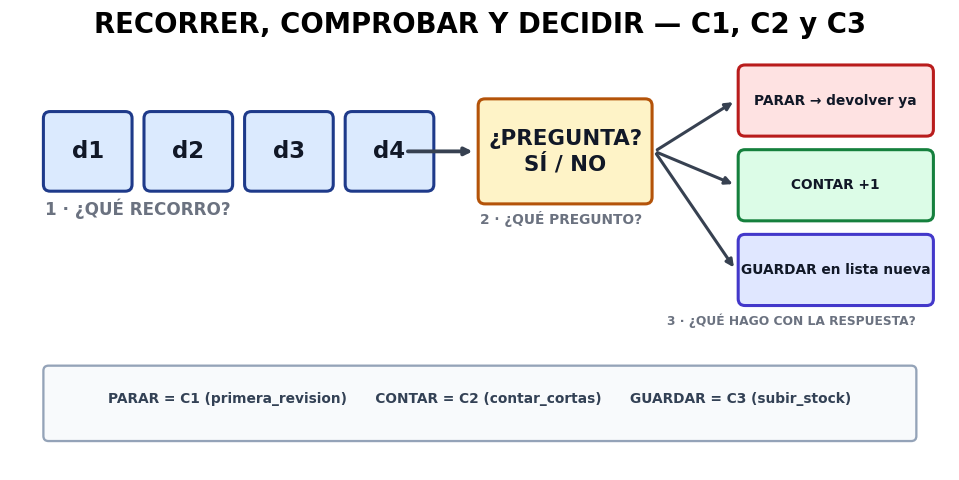

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/pizarra_maquina.png")))

## C1 · La primera bici que se pasa del límite

La primera escena es la fila de bicis de primera hora. Marina ha medido el desgaste de las pastillas de freno y ha apuntado un número por bici, en el orden de la cola: `[3, 8, 12, 6, 10]`. El límite de seguridad es 10. Queremos encontrar la primera bici que se pasa.

Aquí conviene afinar la pregunta. No buscamos el valor de la medición; buscamos la posición en la fila. Si miráramos el valor, diríamos 12. Pero la primera posición es la 0, así que la respuesta correcta es 2. Si ninguna medición supera el límite, la función devuelve -1. Y una medición de exactamente 10 no supera nada: la comparación es `>`, no `>=`.

Vamos a hacerlo primero como personas. Pongo el dedo en la primera caja:

—¿3 es mayor que 10? No.  
—¿8 es mayor que 10? No.  
—¿12 es mayor que 10? Sí. Ya puedo responder: posición 2.

¿Tiene sentido seguir mirando el 6 y el 10? En este ejercicio, no. Ya hemos encontrado la primera. Ese «paro en cuanto lo sé» se convertirá después en un `return` dentro del `if`.

Ahora cambio la fila por `[3, 8]`. El dedo recorre las dos cajas, no encuentra ninguna que supere el límite y acaba fuera de la fila. Ese final sin respuesta es el `return -1`.

En la pizarra dibujo cada caja con dos etiquetas: arriba la medición y debajo la posición. Es la versión en cajas de la bici y la percha: la bici es el valor, la percha es el sitio que ocupa. Después veremos el GIF y, cuando podamos decir la receta sin mirarla, escribiremos `primera_revision(mediciones, limite)`.

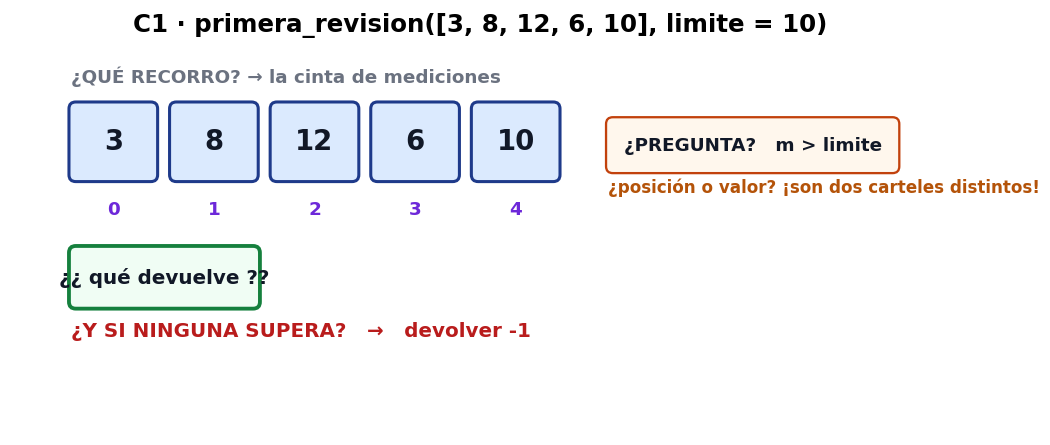

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c1_inicial.png")))

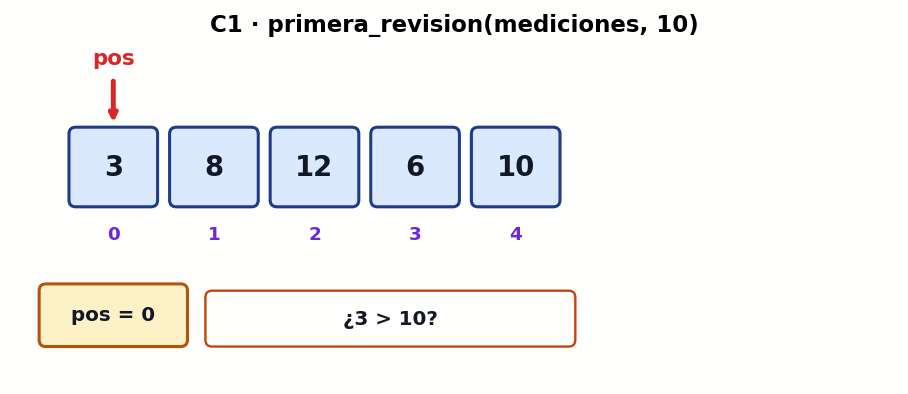

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "gifs/c1_primera_revision.gif"), format="gif"))

### Antes de escribirlo bien, lo decimos mal

Aquí no quiero respuestas rápidas; quiero que alguien razone en voz alta. Pregunto:

—Si la primera bici ya supera el límite, ¿qué devolvemos?  
—Cero. El dedo todavía no se ha movido.

—Y cuando encontramos el 12, ¿seguimos mirando el resto?  
—No. Si seguimos, una lista como `[3, 8, 12, 15, 10]` acabaría dando 3, pero la primera que se pasaba estaba en la posición 2.

—¿Devolvemos la medición o la posición?  
—La posición. La medición es la bici; la posición es la percha.

Ahora escribo en la pizarra tres versiones equivocadas, porque son las que salen de verdad en los exámenes: poner `return -1` dentro del bucle, usar `>=` en lugar de `>` y devolver `m` en vez de `pos`. No las corrijo de momento. Las ejecutamos y dejamos que los contraejemplos hablen.

In [ ]:
# ❌ ERROR 1: return -1 dentro del bucle (se rinde en la primera)
def mal_dentro(mediciones, limite):
    pos = 0
    for m in mediciones:
        if m > limite:
            return pos
        else:
            return -1
        pos = pos + 1

print("mal_dentro  ->", mal_dentro([3, 8, 12, 6, 10], 10), " (debe ser 2)")


# ❌ ERROR 2: >= en vez de >
def mal_igual(mediciones, limite):
    pos = 0
    for m in mediciones:
        if m >= limite:
            return pos
        pos = pos + 1
    return -1

print("mal_igual   ->", mal_igual([10], 10), " (debe ser -1: 10 NO es > 10)")


# ❌ ERROR 3: devuelve el VALOR, no la posición
def mal_valor(mediciones, limite):
    for m in mediciones:
        if m > limite:
            return m
    return -1

print("mal_valor   ->", mal_valor([3, 8, 12, 6, 10], 10), " (debe ser 2)")

mal_dentro  -> -1  (debe ser 2)
mal_igual   -> 0  (debe ser -1: 10 NO es > 10)
mal_valor   -> 12  (debe ser 2)


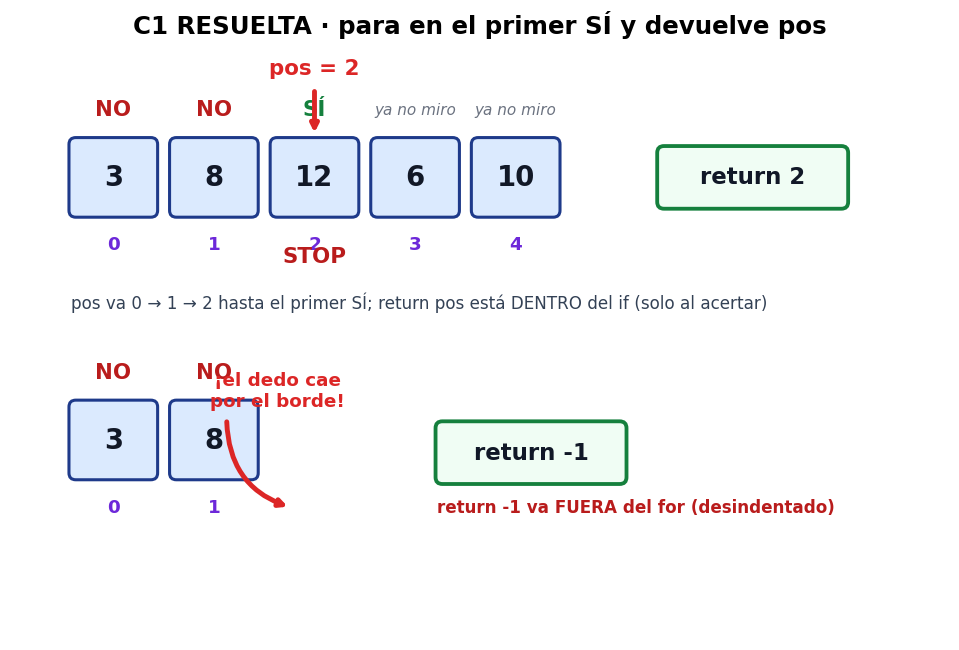

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c1_resuelta.png")))

### De la receta al código

Si ya sabemos decir el recorrido sin mirar la solución, podemos traducirlo. La receta sería más o menos así: empiezo en la posición 0; miro cada medición; si supera el límite, devuelvo esa posición; si no, avanzo una percha; si se acaba la fila, devuelvo -1.

Ahora cada frase se convierte en una línea de Python. La única sangría delicada es la de `return -1`: va fuera del `for`, porque solo se ejecuta cuando el dedo ha llegado al final sin encontrar nada.

In [ ]:
# ✅ SOLUCIÓN — cada renglón se lee del dibujo
def primera_revision(mediciones, limite):
    # pos va contando perchas: 0, 1, 2, ...
    pos = 0
    for m in mediciones:
        if m > limite:
            return pos
        pos = pos + 1
    # el dedo cayó por el borde: ninguna supera el límite
    return -1

print(primera_revision([3, 8, 12, 6, 10], 10))   # 2
print(primera_revision([3, 8], 10))              # -1

2
-1


Antes de fiarnos de la función, probamos las situaciones que suelen romperla: una lista vacía, una primera bici que ya se pasa, una fila en la que ninguna se pasa, una medición igual al límite y otra en la que la primera que se pasa está al final. Digo la respuesta esperada antes de ejecutar cada prueba.

In [ ]:
# lista vacía · la primera pasa · ninguna pasa · límite estricto · la última
pruebas = [([3, 8, 12, 6, 10], 10, 2), ([3, 8], 10, -1), ([], 10, -1),
           ([11], 10, 0), ([10], 10, -1), ([1, 2, 3, 15], 10, 3),
           ([5, 12, 13], 10, 1)]
for meds, lim, esperado in pruebas:
    obtenido = primera_revision(meds, lim)
    assert obtenido == esperado, (meds, lim, obtenido, esperado)
print("todas las pruebas de C1 OK")

todas las pruebas de C1 OK


Si quieres ver la misma traza paso a paso, este enlace abre la función en PythonTutor:
[abrir primera_revision en PythonTutor](https://pythontutor.com/render.html#code=def%20primera_revision%28mediciones%2C%20limite%29%3A%0A%20%20%20%20%23%20pos%20va%20contando%20perchas%3A%200%2C%201%2C%202%2C%20...%0A%20%20%20%20pos%20%3D%200%0A%20%20%20%20for%20m%20in%20mediciones%3A%0A%20%20%20%20%20%20%20%20if%20m%20%3E%20limite%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20pos%0A%20%20%20%20%20%20%20%20pos%20%3D%20pos%20%2B%201%0A%20%20%20%20%23%20el%20dedo%20cay%C3%B3%20por%20el%20borde%3A%20ninguna%20supera%20el%20l%C3%ADmite%0A%20%20%20%20return%20-1%0A%0Aprint%28primera_revision%28%5B3%2C%208%2C%2012%2C%206%2C%2010%5D%2C%2010%29%29&cumulative=false&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=3&rawInputLstJSON=%5B%5D&textReferences=false)

### Mini-reto C1

`ultima_revision(mediciones, limite)` devuelve la posición de la última medición estrictamente mayor que `limite`, o -1 si no hay ninguna.

Ya no vale parar en la primera. Hay que seguir hasta el final e ir recordando la última posición que cumplió la condición.

Si el reto se atraganta, enseño esta versión después de dejar unos minutos de intento. Es la misma idea, pero el `return` ya no interrumpe el recorrido: guardamos la posición y seguimos.

In [ ]:
def ultima_revision(mediciones, limite):
    res = -1          # de momento, ninguna
    pos = 0
    for m in mediciones:
        if m > limite:
            res = pos      # recuerdo la última buena, no paro
        pos = pos + 1
    return res

assert ultima_revision([3, 8, 12, 15, 10], 10) == 3
assert ultima_revision([3, 8], 10) == -1
assert ultima_revision([12, 4, 13], 10) == 2
print("reto C1 OK")

reto C1 OK


## C2 · Las palabras cortas de la nota (~10 min)

En C1 paramos en cuanto encontramos la primera bici que se pasaba. Ahora no buscamos solo una cosa: queremos contar cuántas cumplen una condición.

Sobre el mostrador aparece una nota de cliente: `"rueda pinchada hoy"`. El ejercicio pide contar cuántas palabras son cortas, donde «corta» significa tener una longitud estrictamente menor que `maximo`. Esto ya huele más a examen que a necesidad urgente del taller, pero nos viene bien: si no recurrimos a `split()` desde el principio, tenemos que entender de verdad dónde empieza y dónde acaba una palabra.

```python
contar_cortas("rueda pinchada hoy", 7)   # -> 2   (rueda=5, hoy=3)
contar_cortas("", 5)                     # -> 0
```

Vamos a recorrer el texto carácter a carácter, incluidos los espacios. La nota puede venir con espacios de más al principio, al final o en medio. En la pizarra cada carácter es una caja y los espacios se dibujan como `␣`. Necesitamos dos contadores: `longitud`, que mide la palabra que estamos leyendo, y `contador`, que guarda cuántas palabras cortas llevamos cerradas.

La pregunta importante aparece cuando llega un espacio: ¿la palabra que acaba de terminar tiene `0 < longitud < maximo`? Si la respuesta es sí, sumamos una. Después `longitud` vuelve a cero, sea corta o no, porque empezamos otra palabra.

Queda un detalle que casi siempre se escapa: la última palabra puede no terminar en espacio. Por eso, al salir del bucle, hacemos una última comprobación. Si el texto terminaba en espacio, `longitud` ya vale 0 y esa comprobación no suma nada.

Aquí el separador principal es el espacio ordinario (`" "`). Más adelante compararemos con `split()`, que además separa tabulaciones y saltos de línea; en los ejemplos del examen veremos que coincide.

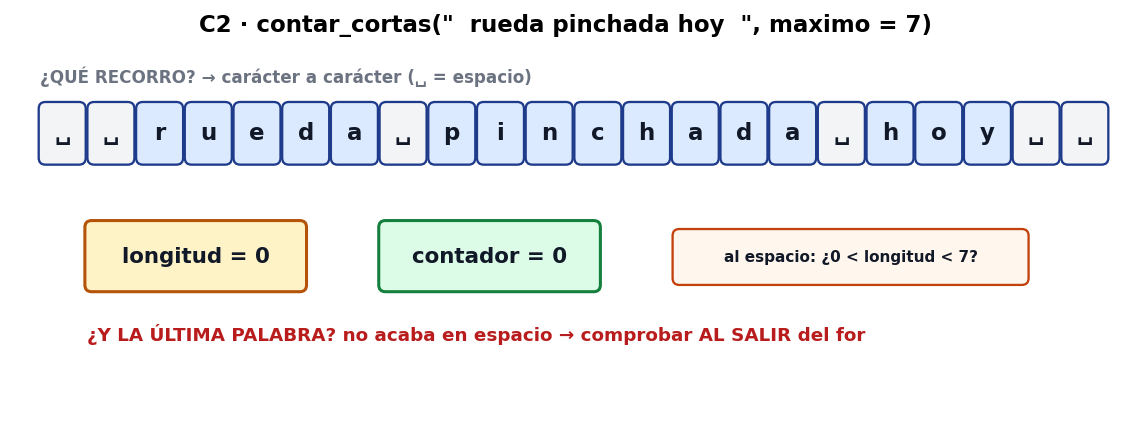

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c2_inicial.png")))

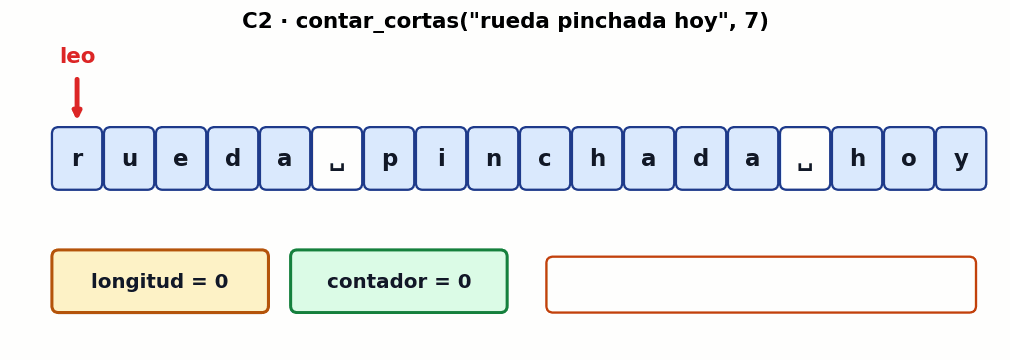

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "gifs/c2_contar_cortas.gif"), format="gif"))

### Las dudas buenas salen antes del código

Pregunto antes de enseñar nada:

—Si el texto está vacío o solo tiene espacios, ¿cuántas palabras cortas hay?  
—Ninguna. No hay ninguna palabra que cerrar.

—Si hay dos espacios seguidos, ¿el segundo cuenta una palabra vacía?  
—No. Cuando llega el segundo espacio, `longitud` vale 0 y la condición `0 < longitud` ya falla.

—Si una palabra tiene exactamente `maximo` letras, ¿cuenta?  
—No. La condición es menor estricto.

También sale la pregunta de si se puede devolver dentro del bucle: no, porque saldríamos al encontrar el primer espacio y dejaríamos medio texto sin mirar.

Después escribo mal las dos versiones típicas. En una cambio `<` por `<=` y `"sieteaa"` con máximo 7 delata el error. En la otra quito la comprobación final y la última palabra de `"rueda pinchada hoy"` desaparece como si no existiera.

In [ ]:
# ❌ ERROR 1: <= en vez de < (cuenta palabras de exactamente maximo)
def mal_igual(texto, maximo):
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if 0 < longitud <= maximo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    if 0 < longitud <= maximo:
        contador = contador + 1
    return contador

print("mal_igual     ->", mal_igual("sieteaa", 7), " (debe ser 0)")


# ❌ ERROR 2: falta el if FINAL (la última palabra se pierde)
def mal_sin_final(texto, maximo):
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if 0 < longitud < maximo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    return contador

print("mal_sin_final ->", mal_sin_final("rueda pinchada hoy", 7),
      " (debe ser 2)")

mal_igual     -> 1  (debe ser 0)
mal_sin_final -> 1  (debe ser 2)


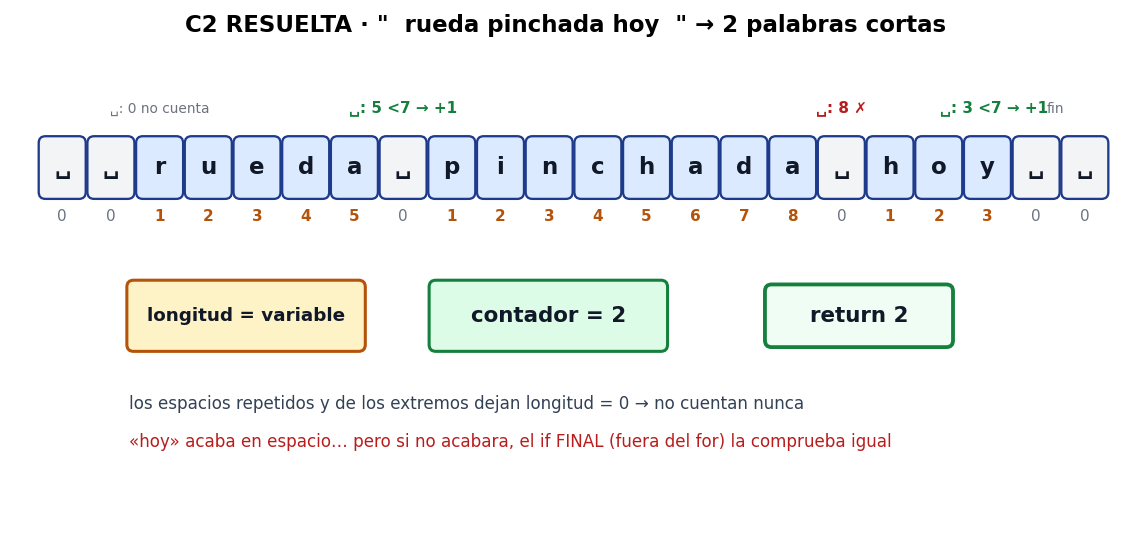

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c2_resuelta.png")))

### De la receta al código

La receta ya casi tiene forma de bucle: empiezo con `contador` y `longitud` a cero; miro cada carácter; si es un espacio, cierro la palabra y decido si cuenta; si no es un espacio, la palabra crece una letra; al terminar el texto, compruebo la última palabra.

Al traducirla hay que vigilar dos sangrías: la comprobación de cada espacio va dentro del `for`, y la comprobación de la última palabra va fuera.

In [ ]:
# ✅ SOLUCIÓN — sin split(): así se ve de verdad qué es una palabra
def contar_cortas(texto, maximo):
    # recorremos carácter a carácter, sin split()
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if 0 < longitud < maximo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    # la última palabra no acaba en espacio: se comprueba al salir
    if 0 < longitud < maximo:
        contador = contador + 1
    return contador

print(contar_cortas("rueda pinchada hoy", 7))   # 2
print(contar_cortas("", 5))                     # 0

2
0


Una vez entendido el recorrido manual, sí tiene sentido enseñar la versión corta con `split()`. En los ejemplos del examen da el mismo resultado y, además, se encarga sola de los espacios repetidos:

In [ ]:
def contar_cortas_corta(texto, maximo):
    contador = 0
    for palabra in texto.split():
        if len(palabra) < maximo:
            contador = contador + 1
    return contador

print(contar_cortas_corta("rueda pinchada hoy", 7))    # 2
print(contar_cortas_corta("  a  bb   ccc ", 4))        # 3: split() se come
                                                     # los espacios extra

2
3


Antes de ejecutar las pruebas, la clase predice cada resultado. Nos interesan sobre todo el texto vacío, los espacios repetidos, una palabra de exactamente `maximo` letras y una última palabra que no termina en espacio.

In [ ]:
pruebas = [("rueda pinchada hoy", 7, 2), ("", 5, 0), ("   ", 5, 0),
           ("  hola  ", 5, 1), ("a  bb   ccc", 4, 3), ("sieteaa", 7, 0),
           ("hoy", 5, 1), ("una dos tres", 4, 2)]
for texto, mx, esperado in pruebas:
    obtenido = contar_cortas(texto, mx)
    assert obtenido == esperado, (texto, mx, obtenido, esperado)
    assert contar_cortas_corta(texto, mx) == esperado
print("todas las pruebas de C2 OK")

todas las pruebas de C2 OK


Para revisar la traza con calma, aquí está la versión manual en PythonTutor:
[abrir contar_cortas en PythonTutor](https://pythontutor.com/render.html#code=def%20contar_cortas%28texto%2C%20maximo%29%3A%0A%20%20%20%20%23%20recorremos%20car%C3%A1cter%20a%20car%C3%A1cter%2C%20sin%20split%28%29%0A%20%20%20%20contador%20%3D%200%0A%20%20%20%20longitud%20%3D%200%0A%20%20%20%20for%20c%20in%20texto%3A%0A%20%20%20%20%20%20%20%20if%20c%20%3D%3D%20%22%20%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20if%200%20%3C%20longitud%20%3C%20maximo%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20%20%20%20%20%20%20%20%20longitud%20%3D%200%0A%20%20%20%20%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20longitud%20%3D%20longitud%20%2B%201%0A%20%20%20%20%23%20la%20%C3%BAltima%20palabra%20no%20acaba%20en%20espacio%3A%20se%20comprueba%20al%20salir%0A%20%20%20%20if%200%20%3C%20longitud%20%3C%20maximo%3A%0A%20%20%20%20%20%20%20%20contador%20%3D%20contador%20%2B%201%0A%20%20%20%20return%20contador%0A%0Aprint%28contar_cortas%28%22rueda%20pinchada%20hoy%22%2C%207%29%29&cumulative=false&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=3&rawInputLstJSON=%5B%5D&textReferences=false)

### Mini-reto C2

`contar_largas(texto, minimo)` cuenta las palabras con longitud estrictamente mayor que `minimo`.

Es el mismo recorrido. Lo único que cambia es la pregunta que nos hacemos cada vez que cerramos una palabra.

Si el reto se atraganta, enseño esta versión después. Conviene compararla línea a línea con `contar_cortas` y mirar qué pocas cosas han cambiado.

In [ ]:
def contar_largas(texto, minimo):
    contador = 0
    longitud = 0
    for c in texto:
        if c == " ":
            if longitud > 0 and longitud > minimo:
                contador = contador + 1
            longitud = 0
        else:
            longitud = longitud + 1
    if longitud > 0 and longitud > minimo:
        contador = contador + 1
    return contador

assert contar_largas("rueda pinchada hoy", 4) == 2
assert contar_largas("", 3) == 0
assert contar_largas("ab cde", 2) == 1
print("reto C2 OK")

reto C2 OK


## C3 · La reposición del almacén (~12 min)

Hasta ahora hemos encontrado una posición y hemos contado palabras. La última escena de la mañana pide otra cosa: transformar cada elemento.

A media mañana llega una caja de piezas. Marina quiere sumar `extra` unidades a cada estantería, pero ninguna puede quedar por encima de `tope`, porque no cabe más stock. Además quiere conservar la hoja original: si la nueva cuenta sale mal, tiene que poder compararla con lo que había antes.

La función `subir_stock(unidades, extra, tope)` devuelve una lista nueva. La original no cambia.

```python
subir_stock([2, 9], 5, 10)   # -> [7, 10]
subir_stock([4], 0, 10)      # -> [4]
subir_stock([], 3, 10)       # -> []
```

En la pizarra dibujo dos filas. Arriba está la hoja original, con un candado: no se toca. Debajo aparece una fila vacía que iremos rellenando en el mismo orden. Cada flecha sale de una cantidad antigua y llega a su cantidad nueva.

Para decidir el valor nuevo dibujo una recta con un muro en `tope`. Si `u + extra` no llega al muro, se guarda tal cual. Si lo supera, choca y se queda en `tope`. En el ejemplo, 2 + 5 queda en 7, pero 9 + 5 llegaría a 14 y el muro lo deja en 10.

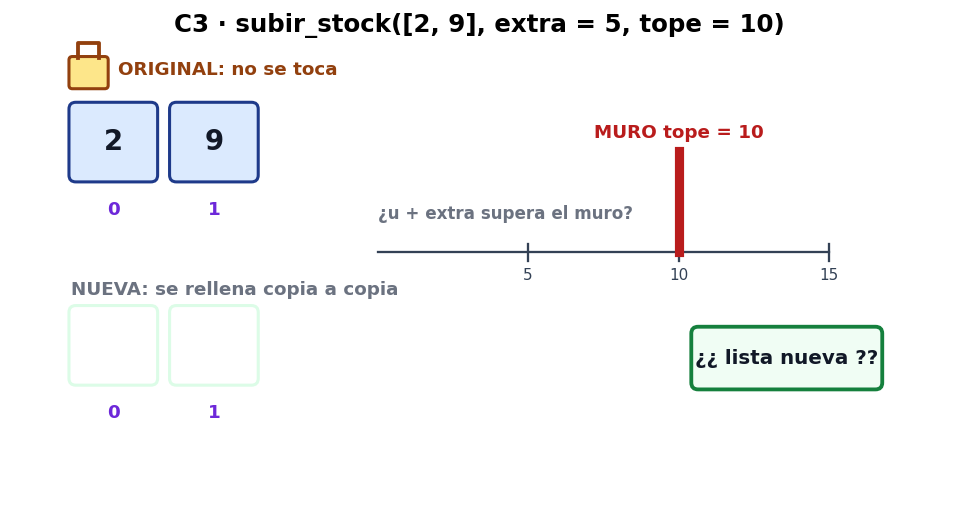

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c3_inicial.png")))

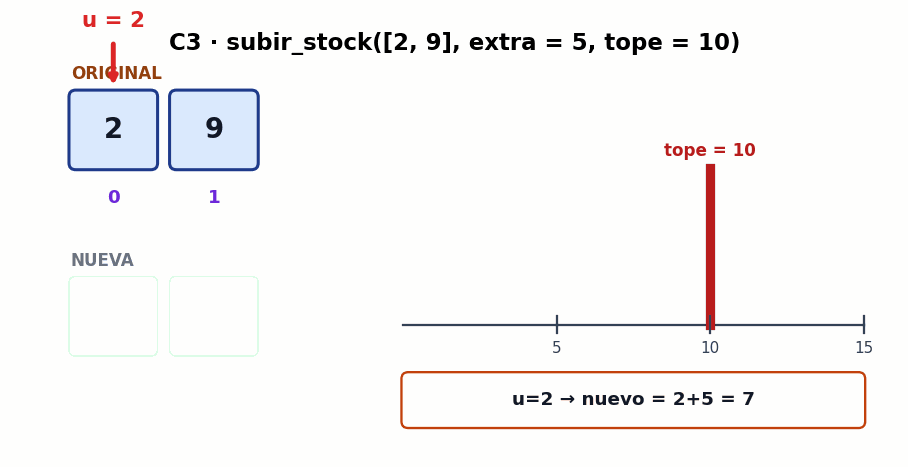

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "gifs/c3_subir_stock.gif"), format="gif"))

### Lo que conviene discutir antes de programar

La primera pregunta viene del taller antes que de Python: ¿por qué no tachamos la hoja original? Porque Marina perdería el registro anterior. En código eso significa que hay que crear una lista nueva.

Después vienen las preguntas rápidas:

—Si `extra` vale 0 y una estantería ya tiene 12 con tope 10, ¿qué pasa?  
—La nueva cantidad queda capada a 10. El muro sigue ahí aunque no hayamos añadido nada.

—¿Puede ser negativo `extra`?  
—Sí. Entonces el stock baja: `[5], -3, 10` produce `[2]`.

Aquí hay dos errores que conviene ver de cerca. Si escribimos `nueva = unidades`, no hemos hecho una copia: hemos puesto dos nombres a la misma lista. Al cambiar `nueva`, también cambia `unidades`. El otro error clásico es poner `return` dentro del bucle; entonces devolvemos solo la primera estantería transformada.

In [ ]:
# ❌ ERROR 1: alias — `nueva = unidades` es LA MISMA lista
def mal_alias(unidades, extra, tope):
    nueva = unidades          # dos nombres, UNA cinta
    for i in range(len(nueva)):
        nuevo = nueva[i] + extra
        if nuevo > tope:
            nuevo = tope
        nueva[i] = nuevo
    return nueva

u = [2, 9]
salida = mal_alias(u, 5, 10)
print("devuelve:", salida, " pero la original quedó:", u, "¡MUTADA!")


# ❌ ERROR 2: return dentro del for (solo transforma el primero)
def mal_return(unidades, extra, tope):
    nueva = []
    for u in unidades:
        nuevo = u + extra
        if nuevo > tope:
            nuevo = tope
        nueva.append(nuevo)
        return nueva

print("mal_return ->", mal_return([2, 9], 5, 10), " (debe ser [7, 10])")

devuelve: [7, 10]  pero la original quedó: [7, 10] ¡MUTADA!
mal_return -> [7]  (debe ser [7, 10])


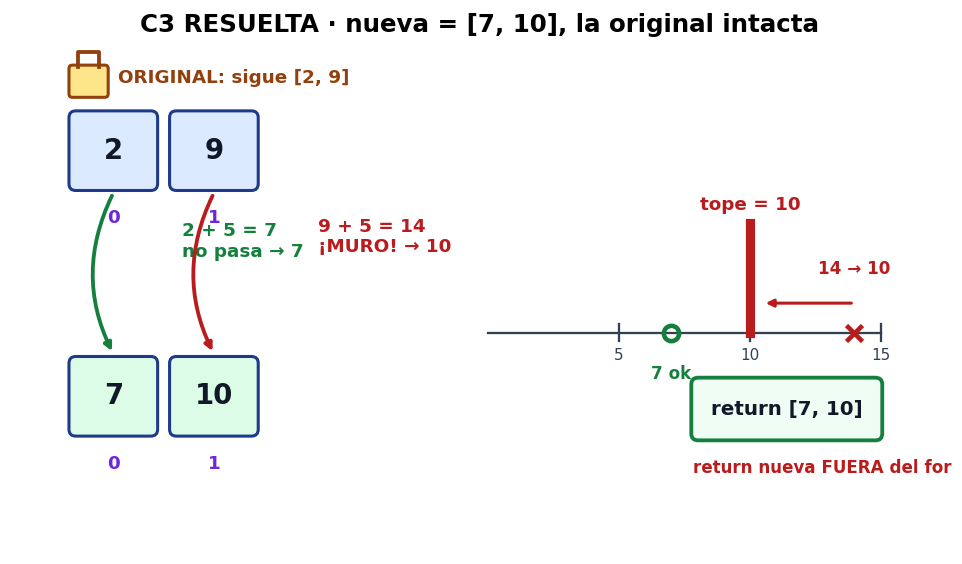

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "figuras/c3_resuelta.png")))

### De la receta al código

La receta es corta: creo una lista nueva vacía; recorro las unidades en orden; sumo `extra`; si el resultado supera el tope, lo dejo en el tope; lo añado a la lista nueva; al terminar, devuelvo esa lista.

La sangría vuelve a contar la mitad de la historia: `append` se hace en cada vuelta, pero `return nueva` espera fuera del `for` a que todas las estanterías estén copiadas.

In [ ]:
# ✅ SOLUCIÓN
def subir_stock(unidades, extra, tope):
    # lista NUEVA: la original no se toca
    nueva = []
    for u in unidades:
        nuevo = u + extra
        if nuevo > tope:
            nuevo = tope
        nueva.append(nuevo)
    return nueva

print(subir_stock([2, 9], 5, 10))   # [7, 10]
print(subir_stock([4], 0, 10))      # [4]
print(subir_stock([], 3, 10))       # []

[7, 10]
[4]
[]


Las pruebas importantes son la lista vacía, el tope exacto, un `extra` negativo y una cantidad que ya estaba por encima del tope. La prueba decisiva es la última: después de llamar a la función, la lista original tiene que seguir exactamente igual.

In [ ]:
pruebas = [([2, 9], 5, 10, [7, 10]), ([4], 0, 10, [4]),
           ([], 3, 10, []), ([12], 0, 10, [10]),   # extra 0: el muro capa
           ([5], -3, 10, [2]),                     # extra negativo: permitido
           ([20], 5, 10, [10]), ([5], 5, 10, [10])]  # tope exacto / superado
for unds, ex, tp, esperado in pruebas:
    obtenido = subir_stock(unds, ex, tp)
    assert obtenido == esperado, (unds, ex, tp, obtenido, esperado)

# la prueba definitiva: la original NO cambia
original = [2, 9]
resultado = subir_stock(original, 5, 10)
assert original == [2, 9], "¡la lista original ha mutado!"
print("todas las pruebas de C3 OK — y la original sigue:", original)

todas las pruebas de C3 OK — y la original sigue: [2, 9]


Para ver cómo se construye la lista nueva paso a paso:
[abrir subir_stock en PythonTutor](https://pythontutor.com/render.html#code=def%20subir_stock%28unidades%2C%20extra%2C%20tope%29%3A%0A%20%20%20%20%23%20lista%20NUEVA%3A%20la%20original%20no%20se%20toca%0A%20%20%20%20nueva%20%3D%20%5B%5D%0A%20%20%20%20for%20u%20in%20unidades%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20u%20%2B%20extra%0A%20%20%20%20%20%20%20%20if%20nuevo%20%3E%20tope%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20nuevo%20%3D%20tope%0A%20%20%20%20%20%20%20%20nueva.append%28nuevo%29%0A%20%20%20%20return%20nueva%0A%0Aprint%28subir_stock%28%5B2%2C%209%5D%2C%205%2C%2010%29%29&cumulative=false&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=3&rawInputLstJSON=%5B%5D&textReferences=false)

### Mini-reto C3

`bajar_stock(unidades, menos, suelo)` devuelve una lista nueva con cada cantidad menos `menos`, sin bajar de `suelo` y sin tocar la original.

Es el mismo recorrido con el muro abajo.

Si el reto se atraganta, enseño esta versión después. La comparación con `subir_stock` ayuda: no cambia el recorrido, cambian la operación y el lado del muro.

In [ ]:
def bajar_stock(unidades, menos, suelo):
    nueva = []
    for u in unidades:
        nuevo = u - menos
        if nuevo < suelo:
            nuevo = suelo
        nueva.append(nuevo)
    return nueva

assert bajar_stock([9, 2], 5, 3) == [4, 3]
assert bajar_stock([], 5, 3) == []
assert bajar_stock([10], -2, 3) == [12]   # menos negativo también sube
print("reto C3 OK")

reto C3 OK


## Cierre · Tres escenas, un mismo recorrido

Volvemos a la mañana de Marina. En la primera escena buscábamos una posición y podíamos parar en cuanto la encontrábamos. En la segunda no había una sola respuesta: había que llegar al final contando. En la tercera cada elemento producía un resultado nuevo y había que guardarlo sin tocar la hoja original.

La clase dicta y yo escribo la comparación:

| | ¿Qué recorro? | ¿Qué pregunto? | ¿Qué hago con la respuesta? |
|---|---|---|---|
| C1 | mediciones y posiciones | ¿`m > limite`? | paro y devuelvo `pos`; si llego al final, devuelvo -1 |
| C2 | caracteres | al cerrar una palabra, ¿`0 < longitud < maximo`? | cuento una más y reinicio `longitud`; al salir compruebo la última |
| C3 | unidades | ¿`u + extra > tope`? | guardo el valor capado en una lista nueva |

Cierro con seis preguntas rápidas. Las digo antes de enseñar la respuesta:

- `primera_revision([], 10)` → -1
- `primera_revision([10], 10)` → -1, porque 10 no supera 10
- `contar_cortas("   ", 5)` → 0
- `contar_cortas("hoy", 5)` → 1, porque la última palabra se comprueba al salir
- `subir_stock([12], 0, 10)` → `[10]`
- después de `subir_stock(original, 5, 10)`, `original` sigue igual

Si en el examen cambian el taller por una farmacia, una biblioteca o una tienda de cómics, no cambia lo importante. Antes de escribir el bucle hay que responder tres cosas: ¿qué recorro?, ¿qué pregunta me hago en cada paso? y ¿paro, cuento o guardo?

Cuando esas tres respuestas están claras, escribir el código es sobre todo traducirlas.

## Regenerar las figuras

Todas las figuras se generan con `figuras.py` (matplotlib + Pillow, sin
servicios externos). Para regenerarlas desde este cuaderno, ejecútalo con
el directorio del paquete como base:

In [ ]:
# Regenera las figuras sin archivos externos.
FUENTE_FIGURAS = '"""Figuras de pizarra para la Parte C — taller de bicis de Marina.\n\nGenera, sin servicios externos (solo matplotlib + Pillow):\n  - PNGs de pizarra (maquina + inicial/resuelta por ejercicio) en ./figuras\n  - fotogramas PNG por GIF en ./gifs/fotogramas/{c1,c2,c3}\n  - GIFs animados en ./gifs\n\nUso:\n    python3 figuras.py            # regenera todo\n    import figuras; figuras.regenerar_todo()\n"""\nimport io\nfrom pathlib import Path\n\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import FancyBboxPatch\nfrom PIL import Image\n\nBASE = Path(__file__).resolve().parent\nDIR_FIG = BASE / "figuras"\nDIR_GIF = BASE / "gifs"\nDIR_FOT = DIR_GIF / "fotogramas"\n\nCOL = {\n    "caja": "#dbeafe", "borde": "#1e3a8a", "idx": "#6d28d9",\n    "si": "#15803d", "no": "#b91c1c", "dedo": "#dc2626",\n    "out": "#15803d", "muro": "#b91c1c", "nueva": "#dcfce7",\n    "gris": "#6b7280", "warn": "#b45309", "vacio": "#f3f4f6",\n}\n\n# ---------------------------------------------------------------- utilidades\n\ndef _ax(w, h, xlim, ylim):\n    fig, ax = plt.subplots(figsize=(w, h), dpi=110)\n    ax.set_xlim(*xlim)\n    ax.set_ylim(*ylim)\n    ax.axis("off")\n    return fig, ax\n\n\ndef caja(ax, x, y, w, h, texto="", fc=None, ec=None, fs=18, tc="#111827", lw=2):\n    fc = fc or COL["caja"]\n    ec = ec or COL["borde"]\n    ax.add_patch(FancyBboxPatch(\n        (x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",\n        fc=fc, ec=ec, lw=lw))\n    if texto != "":\n        ax.text(x + w / 2, y + h / 2, texto, ha="center", va="center",\n                fontsize=fs, color=tc, fontweight="bold")\n\n\ndef cinta(ax, valores, x0, y, bw=1.0, bh=0.9, gap=0.18, fc=None,\n          idx=True, fs=18, prefijo=""):\n    """Dibuja las cajas de la cinta; devuelve los centros x de cada caja."""\n    fc = fc or COL["caja"]\n    centros = []\n    for i, v in enumerate(valores):\n        x = x0 + i * (bw + gap)\n        caja(ax, x, y, bw, bh, str(v), fc=fc, fs=fs)\n        if idx:\n            ax.text(x + bw / 2, y - 0.24, prefijo + str(i), ha="center",\n                    va="top", fontsize=12, color=COL["idx"], fontweight="bold")\n        centros.append(x + bw / 2)\n    return centros\n\n\ndef dedo(ax, x, y, texto="pos", color=None):\n    color = color or COL["dedo"]\n    ax.annotate("", xy=(x, y + 0.04), xytext=(x, y + 0.6),\n                arrowprops=dict(arrowstyle="-|>", lw=3.2, color=color))\n    ax.text(x, y + 0.72, texto, ha="center", va="bottom", fontsize=14,\n            color=color, fontweight="bold")\n\n\ndef veredicto(ax, x, y, ok):\n    ax.text(x, y, "SÍ" if ok else "NO", ha="center", va="center",\n            fontsize=14, fontweight="bold",\n            color=COL["si"] if ok else COL["no"])\n\n\ndef globo(ax, x, y, w, texto, fc="#fff7ed", ec="#c2410c", fs=12):\n    caja(ax, x, y, w, 0.62, texto, fc=fc, ec=ec, fs=fs, lw=1.5)\n\n\ndef salida(ax, x, y, texto, fs=15):\n    caja(ax, x, y, 2.2, 0.7, texto, fc="#f0fdf4", ec=COL["out"], fs=fs, lw=2.5)\n\n\ndef guardar(fig, nombre):\n    DIR_FIG.mkdir(parents=True, exist_ok=True)\n    fig.savefig(DIR_FIG / nombre, bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n\n\ndef _a_png(fig):\n    buf = io.BytesIO()\n    fig.savefig(buf, format="png", bbox_inches="tight", facecolor="white")\n    plt.close(fig)\n    buf.seek(0)\n    return Image.open(buf).convert("P", palette=Image.ADAPTIVE)\n\n\ndef _gif(frames, carpeta, nombre, duracion=900):\n    """frames: lista de PIL images. Guarda fotogramas PNG y el GIF."""\n    d = DIR_FOT / carpeta\n    d.mkdir(parents=True, exist_ok=True)\n    for v in d.glob("*.png"):\n        v.unlink()\n    imgs = []\n    for i, f in enumerate(frames):\n        f.save(d / f"f{i:02d}.png")\n        imgs.append(f)\n    DIR_GIF.mkdir(parents=True, exist_ok=True)\n    imgs[0].save(DIR_GIF / nombre, save_all=True, append_images=imgs[1:],\n                 duration=duracion, loop=0)\n\n# ------------------------------------------------------------ pizarra maquina\n\ndef fig_maquina():\n    fig, ax = _ax(11, 5.4, (0, 11), (0, 5.4))\n    ax.text(5.5, 5.15, "RECORRER, COMPROBAR Y DECIDIR — C1, C2 y C3",\n            ha="center", fontsize=18, fontweight="bold")\n\n    xs = cinta(ax, ["d1", "d2", "d3", "d4"], 0.4, 3.3, idx=False, fs=15)\n    ax.text(0.4, 3.0, "1 · ¿QUÉ RECORRO?", fontsize=11,\n            color=COL["gris"], fontweight="bold")\n\n    caja(ax, 5.5, 3.15, 2.0, 1.2, "¿PREGUNTA?\\nSÍ / NO",\n         fc="#fef3c7", ec=COL["warn"], fs=14)\n    ax.text(5.5, 2.9, "2 · ¿QUÉ PREGUNTO?", fontsize=9,\n            color=COL["gris"], fontweight="bold")\n    ax.annotate("", xy=(5.45, 3.75), xytext=(4.62, 3.75),\n                arrowprops=dict(arrowstyle="-|>", lw=2.5, color="#374151"))\n\n    for y, t, fc, ec in [\n        (3.95, "PARAR → devolver ya", "#fee2e2", "#b91c1c"),\n        (2.95, "CONTAR +1", "#dcfce7", "#15803d"),\n        (1.95, "GUARDAR en lista nueva", "#e0e7ff", "#4338ca"),\n    ]:\n        caja(ax, 8.55, y, 2.25, 0.8, t, fc=fc, ec=ec, fs=9)\n    for y in (4.35, 3.35, 2.35):\n        ax.annotate("", xy=(8.5, y), xytext=(7.55, 3.75),\n                    arrowprops=dict(arrowstyle="-|>", lw=2, color="#374151"))\n    ax.text(7.7, 1.7, "3 · ¿QUÉ HAGO CON LA RESPUESTA?", fontsize=8,\n            color=COL["gris"], fontweight="bold")\n\n    ax.add_patch(FancyBboxPatch((0.4, 0.35), 10.2, 0.85,\n                 boxstyle="round,pad=0.02,rounding_size=0.06",\n                 fc="#f8fafc", ec="#94a3b8", lw=1.5))\n    ax.text(5.5, 0.78,\n            "PARAR = C1 (primera_revision)      CONTAR = C2 (contar_cortas)      GUARDAR = C3 (subir_stock)",\n            ha="center", fontsize=9, fontweight="bold", color="#334155")\n    guardar(fig, "pizarra_maquina.png")\n\n# ---------------------------------------------------------------- C1 pizarras\n\nDATOS_C1 = [3, 8, 12, 6, 10]\n\ndef fig_c1_inicial():\n    fig, ax = _ax(11, 5.0, (0, 11), (0, 5.0))\n    ax.text(5.5, 4.75, "C1 · primera_revision([3, 8, 12, 6, 10], limite = 10)",\n            ha="center", fontsize=16, fontweight="bold")\n\n    cinta(ax, DATOS_C1, 0.7, 3.0)\n    ax.text(0.7, 4.15, "¿QUÉ RECORRO? → la cinta de mediciones", fontsize=12,\n            color=COL["gris"], fontweight="bold")\n    globo(ax, 7.0, 3.1, 3.4, "¿PREGUNTA?   m > limite")\n    ax.text(7.0, 2.85, "¿posición o valor? ¡son dos carteles distintos!",\n            fontsize=11, color=COL["warn"], fontweight="bold")\n\n    salida(ax, 0.7, 1.5, "¿¿ qué devuelve ??", fs=13)\n    ax.text(0.7, 1.15, "¿Y SI NINGUNA SUPERA?   →   devolver -1",\n            fontsize=13, color=COL["no"], fontweight="bold")\n    guardar(fig, "c1_inicial.png")\n\n\ndef fig_c1_resuelta():\n    fig, ax = _ax(11, 7.4, (0, 11), (0, 7.4))\n    ax.text(5.5, 7.15, "C1 RESUELTA · para en el primer SÍ y devuelve pos",\n            ha="center", fontsize=16, fontweight="bold")\n\n    # --- cinta 1: se para en el indice 2\n    centros = cinta(ax, DATOS_C1, 0.7, 5.0)\n    for i, ok in [(0, False), (1, False), (2, True)]:\n        veredicto(ax, centros[i], 6.25, ok)\n    for i in (3, 4):\n        ax.text(centros[i], 6.25, "ya no miro", ha="center", va="center",\n                fontsize=10, color=COL["gris"], style="italic")\n    dedo(ax, centros[2], 5.9, "pos = 2")\n    ax.text(centros[2], 4.45, "STOP", ha="center", fontsize=14,\n            fontweight="bold", color=COL["no"])\n    salida(ax, 7.6, 5.1, "return 2")\n\n    ax.text(0.7, 3.9, "pos va 0 → 1 → 2 hasta el primer SÍ; "\n                      "return pos está DENTRO del if (solo al acertar)",\n            fontsize=11, color="#334155")\n\n    # --- cinta 2: ninguna supera -> dedo cae por el borde\n    c2 = cinta(ax, [3, 8], 0.7, 1.9)\n    for i in (0, 1):\n        veredicto(ax, c2[i], 3.15, False)\n    x_fin = c2[-1] + 0.9\n    ax.annotate("", xy=(x_fin, 1.55), xytext=(c2[-1] + 0.15, 2.6),\n                arrowprops=dict(arrowstyle="-|>", lw=3.2, color=COL["dedo"],\n                                connectionstyle="arc3,rad=0.35"))\n    ax.text(x_fin - 0.15, 2.75, "¡el dedo cae\\npor el borde!", ha="center",\n            fontsize=12, color=COL["dedo"], fontweight="bold")\n    salida(ax, 5.0, 1.85, "return -1")\n    ax.text(5.0, 1.5, "return -1 va FUERA del for (desindentado)",\n            fontsize=11, color=COL["no"], fontweight="bold")\n    guardar(fig, "c1_resuelta.png")\n\n# ---------------------------------------------------------------- C2 pizarras\n\nTEXTO_C2 = "  rueda pinchada hoy  "\n\ndef _cinta_chars(ax, texto, x0, y, bw=0.52, gap=0.06, fs=15):\n    centros = []\n    for i, c in enumerate(texto):\n        x = x0 + i * (bw + gap)\n        visible = c if c != " " else "␣"\n        fc = COL["caja"] if c != " " else COL["vacio"]\n        caja(ax, x, y, bw, 0.7, visible, fc=fc, fs=fs, lw=1.5)\n        centros.append(x + bw / 2)\n    return centros\n\n\ndef fig_c2_inicial():\n    fig, ax = _ax(13, 5.0, (0, 13.2), (0, 5.0))\n    ax.text(6.6, 4.75, \'C2 · contar_cortas("  rueda pinchada hoy  ", maximo = 7)\',\n            ha="center", fontsize=15, fontweight="bold")\n\n    _cinta_chars(ax, TEXTO_C2, 0.35, 3.2)\n    ax.text(0.35, 4.15, "¿QUÉ RECORRO? → carácter a carácter (␣ = espacio)",\n            fontsize=11, color=COL["gris"], fontweight="bold")\n\n    caja(ax, 0.9, 1.7, 2.6, 0.8, "longitud = 0", fc="#fef3c7",\n         ec=COL["warn"], fs=14)\n    caja(ax, 4.4, 1.7, 2.6, 0.8, "contador = 0", fc="#dcfce7",\n         ec=COL["si"], fs=14)\n    globo(ax, 7.9, 1.78, 4.2, "al espacio: ¿0 < longitud < 7?", fs=10)\n\n    ax.text(0.9, 1.1, "¿Y LA ÚLTIMA PALABRA? no acaba en espacio → "\n                      "comprobar AL SALIR del for", fontsize=12,\n            color=COL["no"], fontweight="bold")\n    guardar(fig, "c2_inicial.png")\n\n\ndef fig_c2_resuelta():\n    fig, ax = _ax(13, 6.2, (0, 13.2), (0, 6.2))\n    ax.text(6.6, 5.95, \'C2 RESUELTA · "  rueda pinchada hoy  " → 2 palabras cortas\',\n            ha="center", fontsize=15, fontweight="bold")\n\n    centros = _cinta_chars(ax, TEXTO_C2, 0.35, 4.0)\n    # longitud bajo cada carácter\n    longitud = 0\n    espacios = []\n    for i, c in enumerate(TEXTO_C2):\n        if c == " ":\n            ax.text(centros[i], 3.72, "0", ha="center", fontsize=10,\n                    color=COL["gris"])\n            espacios.append(i)\n            longitud = 0\n        else:\n            longitud += 1\n            ax.text(centros[i], 3.72, str(longitud), ha="center",\n                    fontsize=10, color=COL["warn"], fontweight="bold")\n\n    # veredictos en cada espacio + al final\n    ax.text(centros[2], 5.0, "␣: 0 no cuenta", ha="center", fontsize=9,\n            color=COL["gris"])\n    ax.text(centros[7], 5.0, "␣: 5 <7 → +1", ha="center", fontsize=10,\n            color=COL["si"], fontweight="bold")\n    ax.text(centros[16], 5.0, "␣: 8 ✗", ha="center", fontsize=10,\n            color=COL["no"], fontweight="bold")\n    ax.text(centros[20] - 0.5, 5.0, "␣: 3 <7 → +1", ha="center", fontsize=10,\n            color=COL["si"], fontweight="bold")\n    ax.text(centros[-1] - 0.35, 5.0, "fin", ha="center", fontsize=9,\n            color=COL["gris"])\n\n    caja(ax, 1.4, 2.2, 2.8, 0.8, "longitud = variable", fc="#fef3c7",\n         ec=COL["warn"], fs=12)\n    caja(ax, 5.0, 2.2, 2.8, 0.8, "contador = 2", fc="#dcfce7",\n         ec=COL["si"], fs=14)\n    salida(ax, 9.0, 2.25, "return 2", fs=14)\n\n    ax.text(1.4, 1.5,\n            "los espacios repetidos y de los extremos dejan longitud = 0 → "\n            "no cuentan nunca",\n            fontsize=11, color="#334155")\n    ax.text(1.4, 1.05,\n            "«hoy» acaba en espacio… pero si no acabara, el if FINAL "\n            "(fuera del for) la comprueba igual",\n            fontsize=11, color=COL["no"])\n    guardar(fig, "c2_resuelta.png")\n\n# ---------------------------------------------------------------- C3 pizarras\n\ndef _padlock(ax, x, y):\n    ax.add_patch(FancyBboxPatch((x, y), 0.42, 0.34,\n                 boxstyle="round,pad=0.02,rounding_size=0.04",\n                 fc="#fde68a", ec="#92400e", lw=2))\n    ax.plot([x + 0.09, x + 0.09, x + 0.33, x + 0.33],\n            [y + 0.34, y + 0.52, y + 0.52, y + 0.34],\n            color="#92400e", lw=2.5)\n\n\ndef fig_c3_inicial():\n    fig, ax = _ax(11, 6.0, (0, 11), (0, 6.0))\n    ax.text(5.5, 5.75, "C3 · subir_stock([2, 9], extra = 5, tope = 10)",\n            ha="center", fontsize=16, fontweight="bold")\n\n    cinta(ax, [2, 9], 0.7, 4.0)\n    _padlock(ax, 0.7, 5.1)\n    ax.text(1.25, 5.25, "ORIGINAL: no se toca", fontsize=12,\n            color="#92400e", fontweight="bold")\n\n    # cinta nueva vacía\n    for i in range(2):\n        caja(ax, 0.7 + i * 1.18, 1.6, 1.0, 0.9, "", fc="white",\n             ec=COL["nueva"], fs=14)\n        ax.text(1.2 + i * 1.18, 1.36, str(i), ha="center", va="top",\n                fontsize=12, color=COL["idx"], fontweight="bold")\n    ax.text(0.7, 2.65, "NUEVA: se rellena copia a copia", fontsize=12,\n            color=COL["gris"], fontweight="bold")\n\n    # muro del tope en una recta numérica\n    ax.plot([4.3, 9.6], [3.15, 3.15], color="#334155", lw=1.5)\n    for v in (5, 10, 15):\n        x = 4.3 + v / 15 * 5.3\n        ax.plot([x, x], [3.05, 3.25], color="#334155", lw=1.5)\n        ax.text(x, 2.82, str(v), ha="center", fontsize=10, color="#334155")\n    x_tope = 4.3 + 10 / 15 * 5.3\n    ax.plot([x_tope, x_tope], [3.15, 4.35], color=COL["muro"], lw=6)\n    ax.text(x_tope, 4.5, "MURO tope = 10", ha="center", fontsize=12,\n            color=COL["muro"], fontweight="bold")\n    ax.text(4.3, 3.55, "¿u + extra supera el muro?", fontsize=11,\n            color=COL["gris"], fontweight="bold")\n    salida(ax, 8.0, 1.55, "¿¿ lista nueva ??", fs=13)\n    guardar(fig, "c3_inicial.png")\n\n\ndef fig_c3_resuelta():\n    fig, ax = _ax(11, 6.4, (0, 11), (0, 6.4))\n    ax.text(5.5, 6.15, "C3 RESUELTA · nueva = [7, 10], la original intacta",\n            ha="center", fontsize=16, fontweight="bold")\n\n    centros = cinta(ax, [2, 9], 0.7, 4.3)\n    _padlock(ax, 0.7, 5.4)\n    ax.text(1.25, 5.55, "ORIGINAL: sigue [2, 9]", fontsize=12,\n            color="#92400e", fontweight="bold")\n\n    for i, v in enumerate([7, 10]):\n        caja(ax, 0.7 + i * 1.18, 1.4, 1.0, 0.9, str(v), fc=COL["nueva"], fs=18)\n        ax.text(1.2 + i * 1.18, 1.16, str(i), ha="center", va="top",\n                fontsize=12, color=COL["idx"], fontweight="bold")\n\n    ax.annotate("", xy=(1.2, 2.35), xytext=(centros[0], 4.25),\n                arrowprops=dict(arrowstyle="-|>", lw=2.5, color=COL["out"],\n                                connectionstyle="arc3,rad=0.25"))\n    ax.text(2.0, 3.5, "2 + 5 = 7\\nno pasa → 7", fontsize=12,\n            color=COL["out"], fontweight="bold")\n    ax.annotate("", xy=(2.38, 2.35), xytext=(centros[1], 4.25),\n                arrowprops=dict(arrowstyle="-|>", lw=2.5, color=COL["muro"],\n                                connectionstyle="arc3,rad=0.25"))\n    ax.text(3.6, 3.55, "9 + 5 = 14\\n¡MURO! → 10", fontsize=12,\n            color=COL["muro"], fontweight="bold")\n\n    # recta con muro\n    ax.plot([5.6, 10.2], [2.6, 2.6], color="#334155", lw=1.5)\n    for v in (5, 10, 15):\n        x = 5.6 + v / 15 * 4.6\n        ax.plot([x, x], [2.5, 2.7], color="#334155", lw=1.5)\n        ax.text(x, 2.28, str(v), ha="center", fontsize=10, color="#334155")\n    x_tope = 5.6 + 10 / 15 * 4.6\n    ax.plot([x_tope, x_tope], [2.6, 3.9], color=COL["muro"], lw=6)\n    ax.text(x_tope, 4.05, "tope = 10", ha="center", fontsize=12,\n            color=COL["muro"], fontweight="bold")\n    ax.plot(5.6 + 7 / 15 * 4.6, 2.6, "o", ms=10, color=COL["out"],\n            mfc="none", mew=3)\n    ax.text(5.6 + 7 / 15 * 4.6, 2.05, "7 ok", ha="center", fontsize=11,\n            color=COL["out"], fontweight="bold")\n    ax.plot(5.6 + 14 / 15 * 4.6, 2.6, "x", ms=11, color=COL["muro"], mew=3)\n    ax.annotate("", xy=(x_tope + 0.15, 2.95), xytext=(5.6 + 14 / 15 * 4.6, 2.95),\n                arrowprops=dict(arrowstyle="-|>", lw=2, color=COL["muro"]))\n    ax.text(5.6 + 14 / 15 * 4.6, 3.3, "14 → 10", ha="center", fontsize=11,\n            color=COL["muro"], fontweight="bold")\n\n    salida(ax, 8.0, 1.35, "return [7, 10]", fs=13)\n    ax.text(8.0, 0.95, "return nueva FUERA del for", fontsize=11,\n            color=COL["no"], fontweight="bold")\n    guardar(fig, "c3_resuelta.png")\n\n# ------------------------------------------------------------------ GIF C1\n\ndef _frame_c1(paso):\n    """paso: 0..10 (ver _gif_c1)."""\n    fig, ax = _ax(10.4, 4.4, (0, 10.4), (0, 4.4))\n    datos, limite = DATOS_C1, 10\n    ax.text(5.2, 4.15, "C1 · primera_revision(mediciones, 10)",\n            ha="center", fontsize=15, fontweight="bold")\n    caja(ax, 0.35, 0.45, 1.7, 0.7, f"pos = {min(paso // 2, 2)}",\n         fc="#fef3c7", ec=COL["warn"], fs=13)\n    fases = [(0, "¿3 > 10?"), (1, "NO → pos=1"), (2, "¿8 > 10?"),\n             (3, "NO → pos=2"), (4, "¿12 > 10?"), (5, "¡SÍ!"),\n             (6, "return pos → 2"), (7, "otra cinta: [3, 8]"),\n             (8, "NO, NO…"), (9, "¡cae por el borde!"),\n             (10, "return -1")]\n    globo(ax, 2.3, 0.45, 4.3, fases[paso][1], fs=13)\n\n    if paso <= 6:\n        centros = cinta(ax, datos, 0.7, 2.1)\n        marcados = {0: False, 1: False, 2: True}\n        for i in range(3):\n            if paso // 2 > i or (paso // 2 == i and paso >= 5):\n                veredicto(ax, centros[i], 3.35, marcados[i])\n        if paso == 6:\n            salida(ax, 7.6, 2.2, "return 2", fs=14)\n            dedo(ax, centros[2], 3.0, "pos = 2")\n        else:\n            i = min(paso // 2, 2)\n            dedo(ax, centros[i], 3.0, "pos")\n    else:\n        centros = cinta(ax, [3, 8], 0.7, 2.1)\n        if paso >= 8:\n            veredicto(ax, centros[0], 3.35, False)\n            veredicto(ax, centros[1], 3.35, False)\n        if paso == 8:\n            dedo(ax, centros[1], 3.0, "pos = 2")\n        if paso >= 9:\n            xf = centros[-1] + 0.9\n            ax.annotate("", xy=(xf, 1.75), xytext=(centros[-1] + 0.15, 2.85),\n                        arrowprops=dict(arrowstyle="-|>", lw=3,\n                                        color=COL["dedo"],\n                                        connectionstyle="arc3,rad=0.35"))\n            ax.text(xf - 0.1, 3.05, "¡cae!", ha="center", fontsize=12,\n                    color=COL["dedo"], fontweight="bold")\n        if paso == 10:\n            salida(ax, 5.2, 2.15, "return -1", fs=14)\n    return _a_png(fig)\n\n\ndef _gif_c1():\n    frames = [_frame_c1(p) for p in range(11)]\n    frames.append(frames[-1])  # retiene el final\n    _gif(frames, "c1", "c1_primera_revision.gif", duracion=950)\n\n# ------------------------------------------------------------------ GIF C2\n\nTEXTO_GIF_C2 = "rueda pinchada hoy"\n\ndef _frame_c2(paso):\n    fig, ax = _ax(11.6, 4.0, (0, 11.6), (0, 4.0))\n    texto, maximo = TEXTO_GIF_C2, 7\n    ax.text(5.8, 3.8, f\'C2 · contar_cortas("{texto}", {maximo})\',\n            ha="center", fontsize=14, fontweight="bold")\n    centros = _cinta_chars(ax, texto, 0.5, 1.9, bw=0.55)\n\n    # recalcular estado en el carácter `paso`\n    longitud, contador = 0, 0\n    evento = ""\n    for i in range(min(paso, len(texto))):\n        c = texto[i]\n        if c == " ":\n            evento = f"␣ ¿0<{longitud}<{maximo}? "\n            if 0 < longitud < maximo:\n                contador += 1\n                evento += "SÍ +1"\n            else:\n                evento += "NO"\n            longitud = 0\n        else:\n            longitud += 1\n            evento = f"+1 letra → longitud {longitud}"\n    if paso >= len(texto):\n        evento = f"FIN: última palabra ¿0<{longitud}<{maximo}? "\n        if 0 < longitud < maximo:\n            contador += 1\n            evento += "SÍ +1"\n        else:\n            evento += "NO"\n\n    # longitud bajo cada carácter ya visto\n    longitud = 0\n    for i in range(min(paso, len(texto))):\n        if texto[i] == " ":\n            longitud = 0\n            ax.text(centros[i], 1.62, "0", ha="center", fontsize=9,\n                    color=COL["gris"])\n        else:\n            longitud += 1\n            ax.text(centros[i], 1.62, str(longitud), ha="center",\n                    fontsize=9, color=COL["warn"], fontweight="bold")\n\n    if paso < len(texto):\n        dedo(ax, centros[paso], 2.62, "leo")\n    else:\n        dedo(ax, centros[-1], 2.62, "salgo")\n\n    caja(ax, 0.5, 0.45, 2.5, 0.7, f"longitud = {longitud}",\n         fc="#fef3c7", ec=COL["warn"], fs=13)\n    caja(ax, 3.3, 0.45, 2.5, 0.7, f"contador = {contador}",\n         fc="#dcfce7", ec=COL["si"], fs=13)\n    globo(ax, 6.3, 0.45, 5.0, evento, fs=12)\n    if paso >= len(texto):\n        salida(ax, 7.0, 2.8, f"return {contador}", fs=13)\n    return _a_png(fig)\n\n\ndef _gif_c2():\n    n = len(TEXTO_GIF_C2)\n    frames = [_frame_c2(p) for p in range(n + 1)]\n    frames.append(frames[-1])\n    _gif(frames, "c2", "c2_contar_cortas.gif", duracion=750)\n\n# ------------------------------------------------------------------ GIF C3\n\ndef _frame_c3(paso):\n    fig, ax = _ax(10.4, 5.0, (0, 10.4), (0, 5.0))\n    unidades, extra, tope = [2, 9], 5, 10\n    ax.text(5.2, 4.8, "C3 · subir_stock([2, 9], extra = 5, tope = 10)",\n            ha="center", fontsize=15, fontweight="bold")\n\n    centros = cinta(ax, unidades, 0.7, 3.4)\n    ax.text(0.7, 4.45, "ORIGINAL", fontsize=11, color="#92400e",\n            fontweight="bold")\n\n    nueva = []\n    pasos_txt = ["u=2 → nuevo = 2+5 = 7", "7 ≤ 10 → append → nueva=[7]",\n                 "u=9 → nuevo = 9+5 = 14", "14 > 10 ¡MURO! → nuevo = 10",\n                 "append → nueva=[7, 10]", "return nueva → [7, 10]  "\n                 "(original intacta)"]\n    if paso >= 2:\n        nueva.append(7)\n    if paso >= 4:\n        nueva.append(10)\n\n    for i, v in enumerate(nueva):\n        caja(ax, 0.7 + i * 1.18, 1.2, 1.0, 0.9, str(v), fc=COL["nueva"])\n        ax.text(1.2 + i * 1.18, 0.96, str(i), ha="center", va="top",\n                fontsize=12, color=COL["idx"], fontweight="bold")\n    if not nueva:\n        for i in range(2):\n            caja(ax, 0.7 + i * 1.18, 1.2, 1.0, 0.9, "", fc="white",\n                 ec=COL["nueva"], lw=1.5)\n    ax.text(0.7, 2.25, "NUEVA", fontsize=11, color=COL["gris"],\n            fontweight="bold")\n\n    if paso == 0:\n        dedo(ax, centros[0], 4.3, "u = 2")\n    elif 2 <= paso <= 4:\n        dedo(ax, centros[1], 4.3, "u = 9")\n\n    # muro\n    ax.plot([4.6, 10.0], [1.55, 1.55], color="#334155", lw=1.5)\n    x_tope = 4.6 + 10 / 15 * 5.4\n    ax.plot([x_tope, x_tope], [1.55, 3.4], color=COL["muro"], lw=6)\n    ax.text(x_tope, 3.55, "tope = 10", ha="center", fontsize=11,\n            color=COL["muro"], fontweight="bold")\n    for v in (5, 10, 15):\n        x = 4.6 + v / 15 * 5.4\n        ax.plot([x, x], [1.45, 1.65], color="#334155", lw=1.5)\n        ax.text(x, 1.22, str(v), ha="center", fontsize=10, color="#334155")\n    if 1 <= paso <= 2:\n        ax.plot(4.6 + 7 / 15 * 5.4, 1.55, "o", ms=10, color=COL["out"],\n                mfc="none", mew=3)\n    if paso >= 3:\n        ax.plot(4.6 + 14 / 15 * 5.4, 1.55, "x", ms=11, color=COL["muro"],\n                mew=3)\n        ax.annotate("", xy=(x_tope + 0.12, 1.9),\n                    xytext=(4.6 + 14 / 15 * 5.4, 1.9),\n                    arrowprops=dict(arrowstyle="-|>", lw=2, color=COL["muro"]))\n\n    globo(ax, 4.6, 0.35, 5.4, pasos_txt[paso], fs=12)\n    return _a_png(fig)\n\n\ndef _gif_c3():\n    frames = [_frame_c3(p) for p in range(6)]\n    frames.append(frames[-1])\n    _gif(frames, "c3", "c3_subir_stock.gif", duracion=1100)\n\n# ------------------------------------------------------------------- orquesta\n\ndef regenerar_todo():\n    DIR_FIG.mkdir(parents=True, exist_ok=True)\n    fig_maquina()\n    fig_c1_inicial(); fig_c1_resuelta()\n    fig_c2_inicial(); fig_c2_resuelta()\n    fig_c3_inicial(); fig_c3_resuelta()\n    _gif_c1(); _gif_c2(); _gif_c3()\n    print("Figuras, fotogramas y GIFs regenerados en", BASE)\n\n\nif __name__ == "__main__":\n    regenerar_todo()\n'
(RAIZ / "figuras.py").write_text(FUENTE_FIGURAS, encoding="utf-8")
import runpy
_ = runpy.run_path(str(RAIZ / "figuras.py"), run_name="__main__")  # "_ =" evita volcar el diccionario de globals

Figuras, fotogramas y GIFs regenerados en /tmp/parte_c_pizarra


## Contenido del paquete

```
parte-C-pizarra-devin-web-SWE2/
├── cuaderno/parte-C-pizarra-devin-web-SWE2.ipynb   ← cuaderno original del paquete (esta v2 es un archivo aparte)
├── figuras/            PNGs de pizarra (máquina + inicial/resuelta ×3)
├── excalidraw/         pizarras editables (.excalidraw)
├── gifs/               animaciones + fotogramas PNG por ejercicio
├── guion/              guion TXT para consultar en el móvil
├── chuleta/            chuleta de referencia rápida (md/html)
├── revision/           documento de revisión (html/pdf)
├── codigo/             soluciones.py + errores.py
├── figuras.py          regenera PNGs, fotogramas y GIFs
├── excalidraw_gen.py   regenera los .excalidraw
├── cuaderno_gen.py     regenera el cuaderno original
└── generar_paquete.py  regenera el paquete completo
```

In [ ]:
#@title Descargar recursos docentes (Excalidraw, GIF, guion y PDF)
import base64
from pathlib import Path
paquete = Path("/tmp/recursos-parte-C.zip")
paquete.write_bytes(base64.b64decode('...'))
try:
    from google.colab import files
    files.download(str(paquete))
except ImportError:
    print("Recursos guardados en", paquete)
